# 04 · Expected Loss
EL = PD × LGD × EAD per loan (lifetime horizon for 36-month loans), back-tested against realised loss on the 2015 out-of-time cohort.

In [1]:
import json, pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
R = '../reports/'; F = R + 'figures/'
res = json.load(open(R + 'results.json'))

In [2]:
pd.DataFrame({k: {m: x for m, x in res['expected_loss'][k].items() if m != 'decomposition'} for k in ['train','oot']})

,train,oot
n_loans,2.629920e+05,2.826150e+05
exposure,3.318131e+09,3.618293e+09
total_el,2.019398e+08,2.207353e+08
el_pct_of_exposure,6.085951e-02,6.100538e-02
mean_pd,1.317570e-01,1.330889e-01
mean_lgd,8.658395e-01,8.660102e-01
mean_ead_ratio,5.480346e-01,5.444319e-01
top10pct_pd_share_of_el,2.010478e-01,2.053566e-01
realised_loss,2.085974e+08,2.673067e+08
realised_loss_pct,6.286595e-02,7.387648e-02


In [3]:
pd.DataFrame({k: res['expected_loss'][k]['decomposition'] for k in ['train','oot']})

,train,oot
pd_ratio_pred_over_actual,0.998791,0.895418
ead_ratio_pred_over_actual_defaults,0.999444,0.975353
lgd_ratio_pred_over_actual_defaults,0.996265,0.988344


,grade,n,exposure,el,mean_pd,mean_lgd,el_pct,share_of_el,realised_loss,realised_pct
0,A,70081,1014118775,3.468038e+07,0.083534,0.864378,0.034198,0.157113,23319808.58,0.022995
1,B,91588,1146513475,6.282291e+07,0.122920,0.868048,0.054795,0.284607,63485466.49,0.055373
2,C,77288,918885075,7.001546e+07,0.158710,0.866814,0.076196,0.317192,92155481.33,0.100291
3,D,32642,401254225,3.753646e+07,0.181869,0.864432,0.093548,0.170052,59892468.33,0.149263
4,E,9415,120976350,1.344539e+07,0.204770,0.857889,0.111141,0.060912,23838639.02,0.197052
5,F,1357,14175550,1.897134e+06,0.227861,0.861548,0.133831,0.008595,3840268.71,0.270908
6,G,244,2369350,3.375900e+05,0.248697,0.864664,0.142482,0.001529,774596.03,0.326923


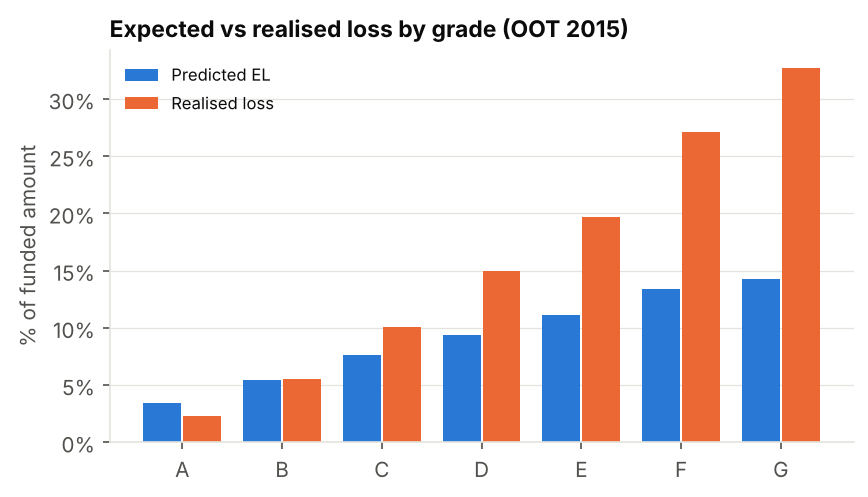

In [4]:
display(pd.read_csv(R + 'el_by_grade_oot.csv')); display(Image(F + 'el_by_grade.png'))

In [5]:
pd.read_csv(R + 'el_by_scoreband_oot.csv')

,score_band,n,exposure,el,mean_pd,mean_lgd,el_pct,share_of_el,realised_loss,realised_pct
0,1,28262,319031075,4.532946e+07,0.271743,0.874068,0.142085,0.205357,52279933.35,0.163871
1,2,28261,318586625,3.266322e+07,0.203778,0.871684,0.102525,0.147975,39492178.97,0.123961
2,3,28262,323705375,2.740190e+07,0.171987,0.870137,0.084651,0.124139,33704148.51,0.104120
3,4,28261,332430075,2.396944e+07,0.149111,0.868698,0.072104,0.108589,30004509.99,0.090258
4,5,28262,340847050,2.108251e+07,0.130202,0.867459,0.061853,0.095510,25866346.25,0.075888
5,6,28261,353396825,1.875868e+07,0.113539,0.865992,0.053081,0.084983,23006057.88,0.065100
6,7,28261,368770575,1.658313e+07,0.097908,0.864416,0.044969,0.075127,20322731.69,0.055109
7,8,28262,385835875,1.435025e+07,0.082568,0.862647,0.037193,0.065011,17838395.25,0.046233
8,9,28261,412382575,1.202168e+07,0.066213,0.860114,0.029152,0.054462,15281564.33,0.037057
9,10,28262,463306750,8.575054e+06,0.043838,0.854886,0.018508,0.038848,9510862.27,0.020528


## Stress test and Monte Carlo loss distribution

In [6]:
display(pd.read_csv(R + 'stress_test_oot.csv')); display(pd.DataFrame(res['expected_loss']['monte_carlo_oot']))

,scenario,el,el_pct,vs_base
0,Base,2.207353e+08,0.061005,0.000000
1,PD x1.5,3.311030e+08,0.091508,0.500000
2,LGD +10pts,2.462835e+08,0.068066,0.115741
3,Combined,3.694253e+08,0.102099,0.673612


,rho,n_sims,analytic_el,sim_mean,q99,q999,ul_99,ul_999
0,0.0,10000,2.207353e+08,2.207356e+08,2.235960e+08,2.244945e+08,2.860451e+06,3.758966e+06
1,0.1,10000,2.207353e+08,2.209389e+08,5.617410e+08,7.188001e+08,3.408021e+08,4.978612e+08


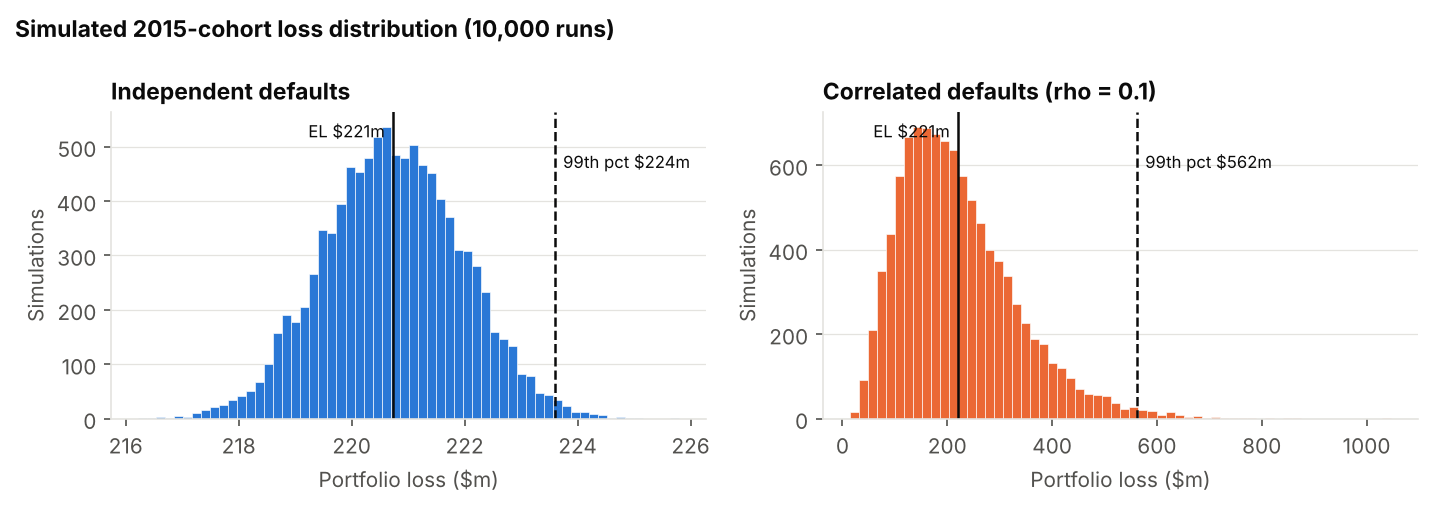

In [7]:
display(Image(F + 'loss_distribution.png'))

## Cohort default curves

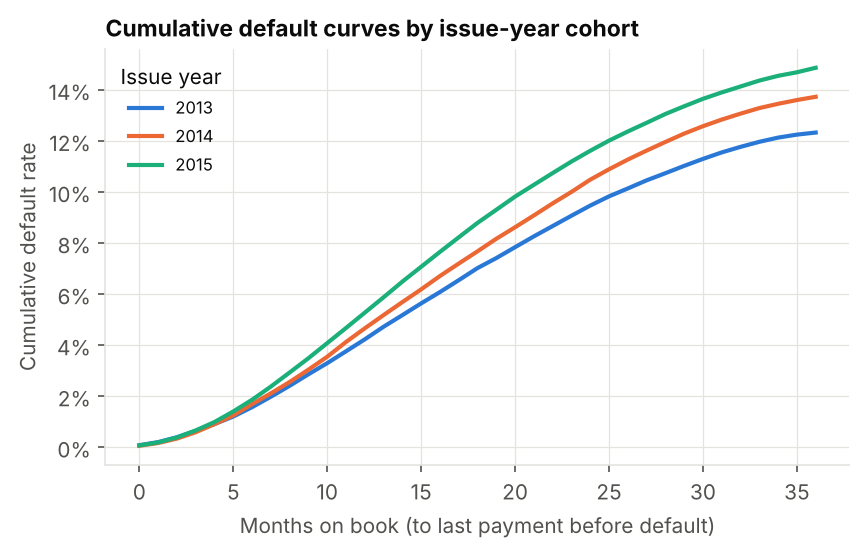

In [8]:
display(Image(F + 'cohort_default_curves.png'))